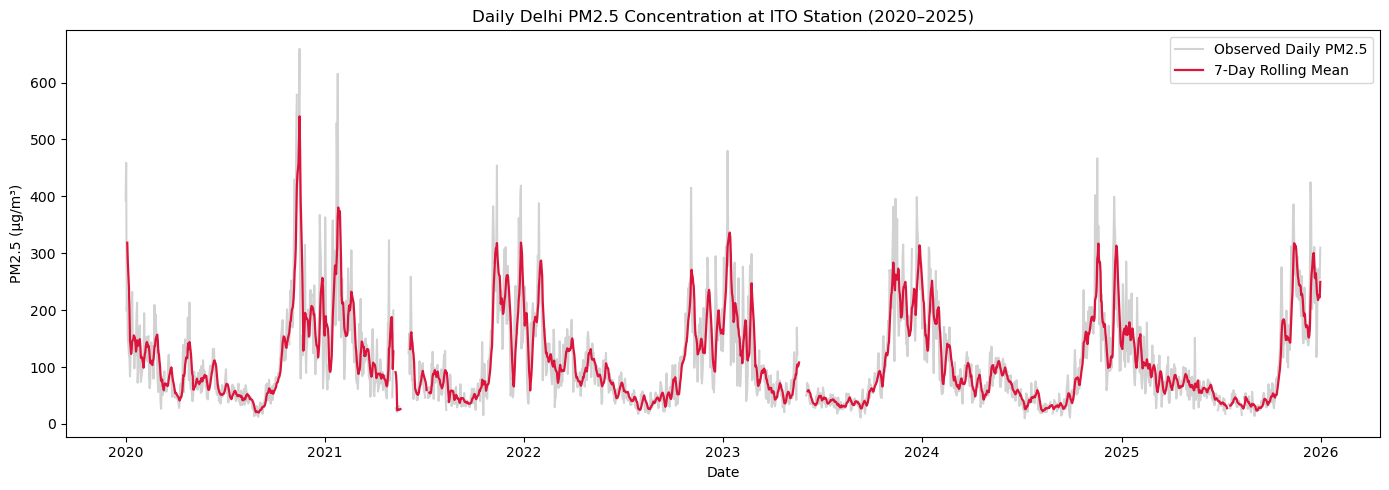

C:\Users\Dell\AppData\Local\Temp\ipykernel_28556\2913916365.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="season", y="PM2.5", palette="Set2")


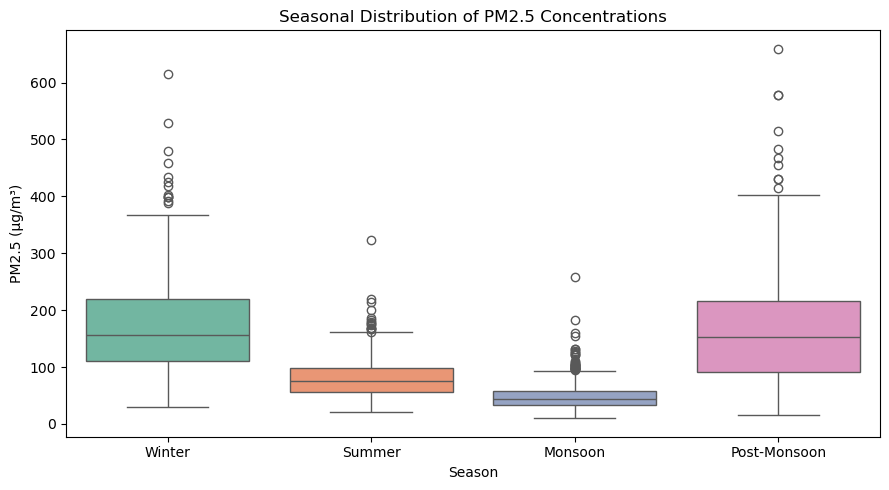

Kruskal-Wallis H-statistic: 1204.017, p-value: 9.8561e-261
Conclusion: Significant variation in PM2.5 across seasons (Reject H0).


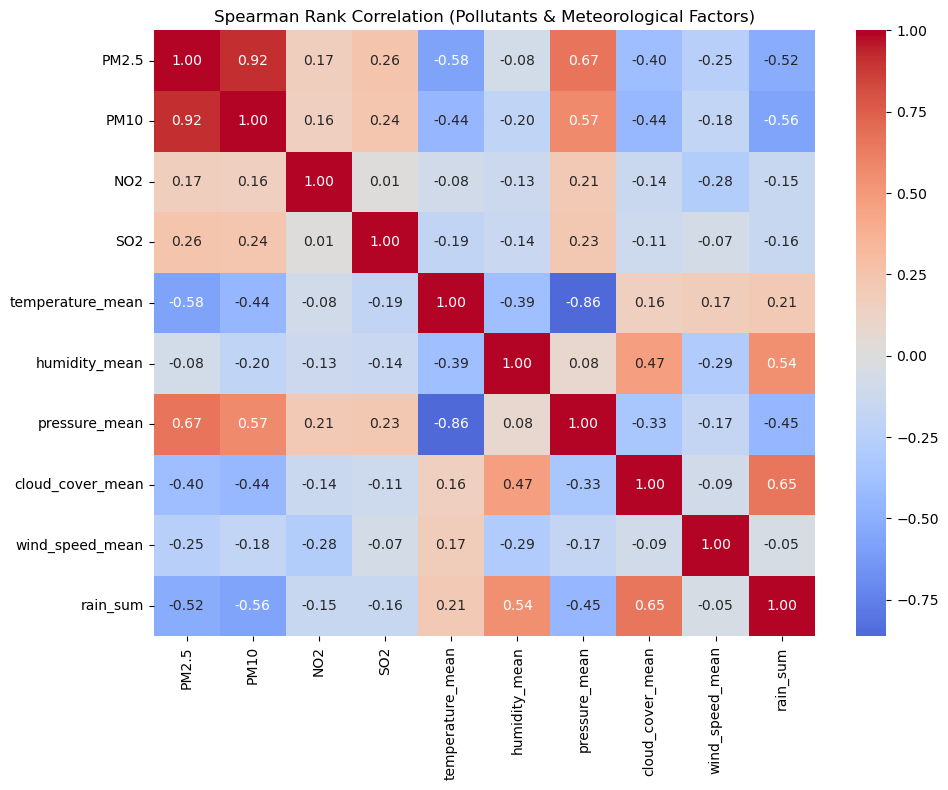

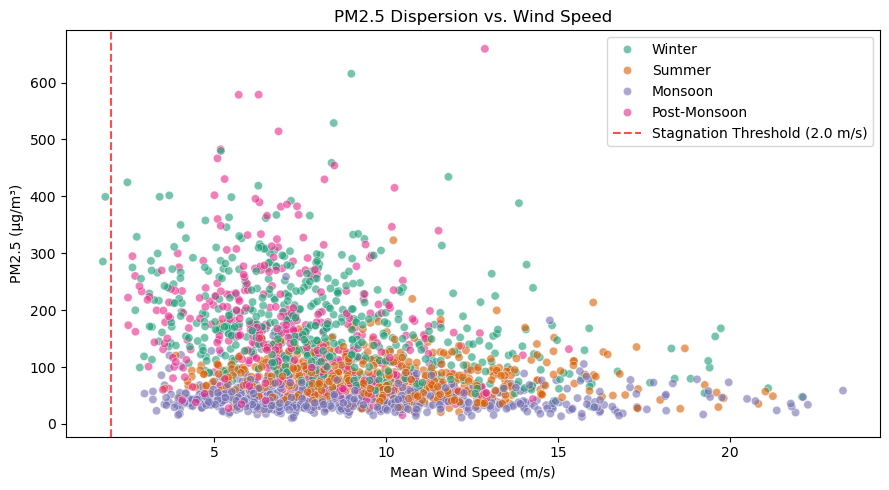

In [14]:
# %% [markdown]
# # Notebook 2: Exploratory Data Analysis & Statistical Testing

# %%
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import kruskal

# Setup output folders
plot_dir = "../plots" if os.path.exists("../plots") or os.path.exists("..") else "plots"
os.makedirs(plot_dir, exist_ok=True)

# %%
# 1. Load processed dataset
candidates = [
    "../data/processed/delhi_pollution_weather_daily_2020_2025.csv",
    "data/processed/delhi_pollution_weather_daily_2020_2025.csv",
    "delhi_pollution_weather_daily_2020_2025.csv"
]
data_path = next(p for p in candidates if os.path.exists(p))
df = pd.read_csv(data_path)
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

# %%
# 2. Historical PM2.5 Trajectory & 7-Day Rolling Mean
df["pm25_roll7"] = df["PM2.5"].rolling(7, min_periods=4).mean()

plt.figure(figsize=(14, 5))
plt.plot(df["Date"], df["PM2.5"], alpha=0.35, color="gray", label="Observed Daily PM2.5")
plt.plot(df["Date"], df["pm25_roll7"], color="crimson", linewidth=1.6, label="7-Day Rolling Mean")
plt.title("Daily Delhi PM2.5 Concentration at ITO Station (2020–2025)")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(plot_dir, "01_pm25_trajectory_rolling.png"), dpi=300)
plt.show()

# %%
# 3. Seasonal Boxplot & Kruskal-Wallis Non-Parametric Test
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="season", y="PM2.5", palette="Set2")
plt.title("Seasonal Distribution of PM2.5 Concentrations")
plt.xlabel("Season")
plt.ylabel("PM2.5 (µg/m³)")
plt.tight_layout()
plt.savefig(os.path.join(plot_dir, "02_seasonal_pm25_boxplot.png"), dpi=300)
plt.show()

# Kruskal-Wallis test (H0: identical median ranks across seasons)
season_subsets = [group["PM2.5"].dropna().values for _, group in df.groupby("season")]
kw_stat, kw_p = kruskal(*season_subsets)
print(f"Kruskal-Wallis H-statistic: {kw_stat:.3f}, p-value: {kw_p:.4e}")
if kw_p < 0.05:
    print("Conclusion: Significant variation in PM2.5 across seasons (Reject H0).")

# %%
# 4. Spearman Rank Correlation Analysis
corr_cols = [
    "PM2.5", "PM10", "NO2", "SO2",
    "temperature_mean", "humidity_mean",
    "pressure_mean", "cloud_cover_mean",
    "wind_speed_mean", "rain_sum"
]
spearman_mat = df[corr_cols].corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(spearman_mat, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar=True)
plt.title("Spearman Rank Correlation (Pollutants & Meteorological Factors)")
plt.tight_layout()
plt.savefig(os.path.join(plot_dir, "03_spearman_correlation_matrix.png"), dpi=300)
plt.show()

# %%
# 5. Wind Speed Dispersion Analysis
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="wind_speed_mean", y="PM2.5", hue="season", alpha=0.6, palette="Dark2")
plt.axvline(x=2.0, color="red", linestyle="--", alpha=0.7, label="Stagnation Threshold (2.0 m/s)")
plt.title("PM2.5 Dispersion vs. Wind Speed")
plt.xlabel("Mean Wind Speed (m/s)")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(plot_dir, "04_wind_dispersion_scatter.png"), dpi=300)
plt.show()